# Customer Segmentation Using K-Means Clustering

## Project Overview

This project performs customer segmentation using the RFM (Recency, Frequency, Monetary) analysis technique and the K-Means clustering algorithm.

The objective is to identify distinct customer groups based on purchasing behavior and provide actionable business insights to improve customer engagement, retention, and marketing strategies.

## Objectives

- Analyze customer purchasing behavior using the Online Retail dataset.
- Perform data cleaning and preprocessing.
- Calculate customer-level RFM metrics.
- Apply feature transformation and scaling.
- Determine the optimal number of clusters.
- Segment customers using K-Means clustering.
- Evaluate clustering performance.
- Analyze customer segments and develop business recommendations.


## 1. Import Libraries and Load Dataset

In this section, the required Python libraries are imported, and the original Online Retail dataset is loaded into a Pandas DataFrame.

The dataset is inspected to understand its structure, dimensions, column names, data types, and initial records before performing data cleaning and preprocessing.

In [1]:

import pandas as pd
import numpy as np


df = pd.read_csv("../data/raw/Online Retail.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


### 1.1 Data Inspection

The dataset is inspected to understand its structure, size, data types, and data quality before performing data cleaning.

The following checks are performed:

- Examine the number of rows and columns.
- Review column names and data types.
- Inspect missing values.
- Identify duplicate records.
- Check invalid Quantity and UnitPrice values.
- Identify cancelled transactions.

These checks help understand the dataset and identify potential data quality issues before preprocessing.

In [2]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Data Types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [3]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing Value Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [4]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 5268


In [5]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

print("\nNegative Quantity:", (df["Quantity"] < 0).sum())
print("Negative UnitPrice:", (df["UnitPrice"] < 0).sum())

Quantity <= 0: 10624
UnitPrice <= 0: 2517

Negative Quantity: 10624
Negative UnitPrice: 2


In [6]:
cancelled_invoices = df["InvoiceNo"].str.startswith("C")

print("Cancelled Invoice Records:", cancelled_invoices.sum())
print("Normal Invoice Records:", (~cancelled_invoices).sum())

Cancelled Invoice Records: 9288
Normal Invoice Records: 532621



## 2. Data Cleaning and Preprocessing

The raw dataset is cleaned and preprocessed to ensure data quality and consistency before performing customer segmentation.

The following preprocessing operations are performed:

- Remove records with missing CustomerID values.
- Remove duplicate records.
- Exclude cancelled transactions.
- Remove records with non-positive Quantity values.
- Remove records with non-positive UnitPrice values.
- Convert InvoiceDate into datetime format.
- Convert CustomerID into integer format.
- Validate the cleaned dataset for missing values and duplicate records.
- Identify the number of unique customers and invoices.

The cleaned dataset is saved as `cleaned_online_retail.csv` for further analysis.



In [7]:
clean_df = df.dropna(subset=["CustomerID"]).copy()

print("Original shape:", df.shape)
print("After removing missing CustomerID:", clean_df.shape)
print("Missing CustomerID:", clean_df["CustomerID"].isnull().sum())

Original shape: (541909, 8)
After removing missing CustomerID: (406829, 8)
Missing CustomerID: 0


In [8]:
clean_df = clean_df.drop_duplicates().copy()

print("Records after removing duplicates:", clean_df.shape)
print("Remaining duplicates:", clean_df.duplicated().sum())

Records after removing duplicates: (401604, 8)
Remaining duplicates: 0


In [9]:
clean_df = clean_df[~clean_df["InvoiceNo"].str.startswith("C")].copy()

print("Records after removing cancelled invoices:", clean_df.shape)
print("Cancelled invoices remaining:", clean_df["InvoiceNo"].str.startswith("C").sum())

Records after removing cancelled invoices: (392732, 8)
Cancelled invoices remaining: 0


In [10]:
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

print("Records after removing invalid quantities/prices:", clean_df.shape)
print("Non-positive quantities:", (clean_df["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (clean_df["UnitPrice"] <= 0).sum())


Records after removing invalid quantities/prices: (392692, 8)
Non-positive quantities: 0
Non-positive unit prices: 0


In [11]:
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")

print(clean_df.dtypes)

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              int64
Country                   str
dtype: object


In [12]:
print("Final Shape:", clean_df.shape)
print("Missing Values:\n", clean_df.isnull().sum())
print("Duplicate Records:", clean_df.duplicated().sum())
print("Unique Customers:", clean_df["CustomerID"].nunique())
print("Unique Invoices:", clean_df["InvoiceNo"].nunique())

Final Shape: (392692, 8)
Missing Values:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Duplicate Records: 0
Unique Customers: 4338
Unique Invoices: 18532


In [13]:
clean_df.to_csv("../data/processed/cleaned_online_retail.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!



## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed on the cleaned Online Retail dataset to understand customer purchasing behavior and transaction patterns.

The following analyses are conducted:

- Examine overall transaction and customer statistics.
- Analyze customer order frequency.
- Calculate total transaction amounts and customer spending.
- Examine the distribution of customer spending.
- Visualize order frequency and spending patterns.

EDA helps identify purchasing behavior and provides a foundation for RFM feature engineering.


In [14]:
print("Total Transactions:", len(clean_df))
print("Total Customers:", clean_df["CustomerID"].nunique())
print("Total Invoices:", clean_df["InvoiceNo"].nunique())
print("Total Products:", clean_df["StockCode"].nunique())
print("Total Countries:", clean_df["Country"].nunique())

print("\nDate Range:")
print("Start Date:", clean_df["InvoiceDate"].min())
print("End Date:", clean_df["InvoiceDate"].max())

Total Transactions: 392692
Total Customers: 4338
Total Invoices: 18532
Total Products: 3665
Total Countries: 37

Date Range:
Start Date: 2010-12-01 08:26:00
End Date: 2011-12-09 12:50:00


In [15]:
customer_orders = clean_df.groupby("CustomerID")["InvoiceNo"].nunique()

print("Average Orders per Customer:", round(customer_orders.mean(), 2))
print("Median Orders per Customer:", customer_orders.median())
print("Maximum Orders by a Customer:", customer_orders.max())
print("Minimum Orders by a Customer:", customer_orders.min())

Average Orders per Customer: 4.27
Median Orders per Customer: 2.0
Maximum Orders by a Customer: 209
Minimum Orders by a Customer: 1


In [16]:
clean_df["TotalAmount"] = clean_df["Quantity"] * clean_df["UnitPrice"]

customer_spending = clean_df.groupby("CustomerID")["TotalAmount"].sum()

print("Average Customer Spending:", round(customer_spending.mean(), 2))
print("Median Customer Spending:", round(customer_spending.median(), 2))
print("Maximum Customer Spending:", round(customer_spending.max(), 2))
print("Minimum Customer Spending:", round(customer_spending.min(), 2))

Average Customer Spending: 2048.69
Median Customer Spending: 668.57
Maximum Customer Spending: 280206.02
Minimum Customer Spending: 3.75


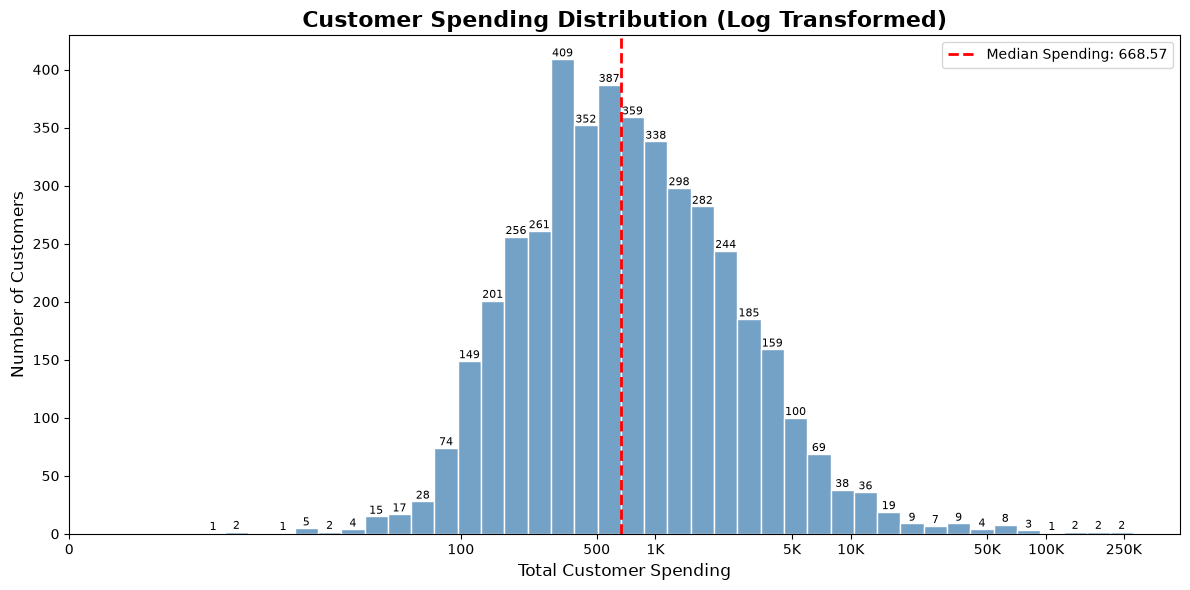

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
spending_log = np.log1p(customer_spending)

median_spending = customer_spending.median()
median_log = np.log1p(median_spending)

plt.figure(figsize=(12, 6))

ax = sns.histplot(
    spending_log,
    bins=40,
    color="steelblue",
    edgecolor="white"
)

# Display customer counts above histogram bars
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (patch.get_x() + patch.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.axvline(
    median_log,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median Spending: {median_spending:,.2f}"
)

ticks = np.log1p([0, 100, 500, 1000, 5000, 10000, 50000, 100000, 250000])
plt.xticks(ticks, ["0", "100", "500", "1K", "5K", "10K", "50K", "100K", "250K"])

plt.title("Customer Spending Distribution (Log Transformed)",
          fontsize=16, fontweight="bold")
plt.xlabel("Total Customer Spending", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.legend()
plt.tight_layout()

plt.savefig(
    "../visualizations/customer_spending_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

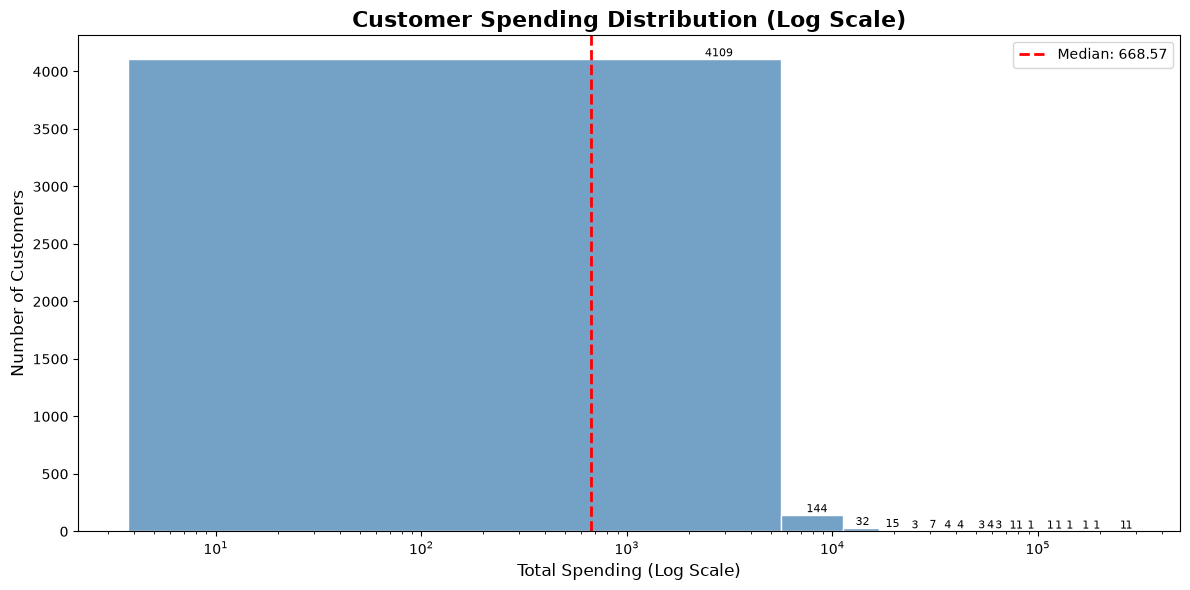

In [18]:
plt.figure(figsize=(12, 6))

ax = sns.histplot(
    customer_spending,
    bins=50,
    color="steelblue",
    edgecolor="white"
)

plt.xscale("log")

# Display customer counts above bars
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (patch.get_x() + patch.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=8
        )

median_spending = customer_spending.median()

plt.axvline(
    median_spending,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_spending:,.2f}"
)

plt.title("Customer Spending Distribution (Log Scale)",
          fontsize=16, fontweight="bold")
plt.xlabel("Total Spending (Log Scale)", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.legend()
plt.tight_layout()

plt.savefig(
    "../visualizations/customer_spending_log_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

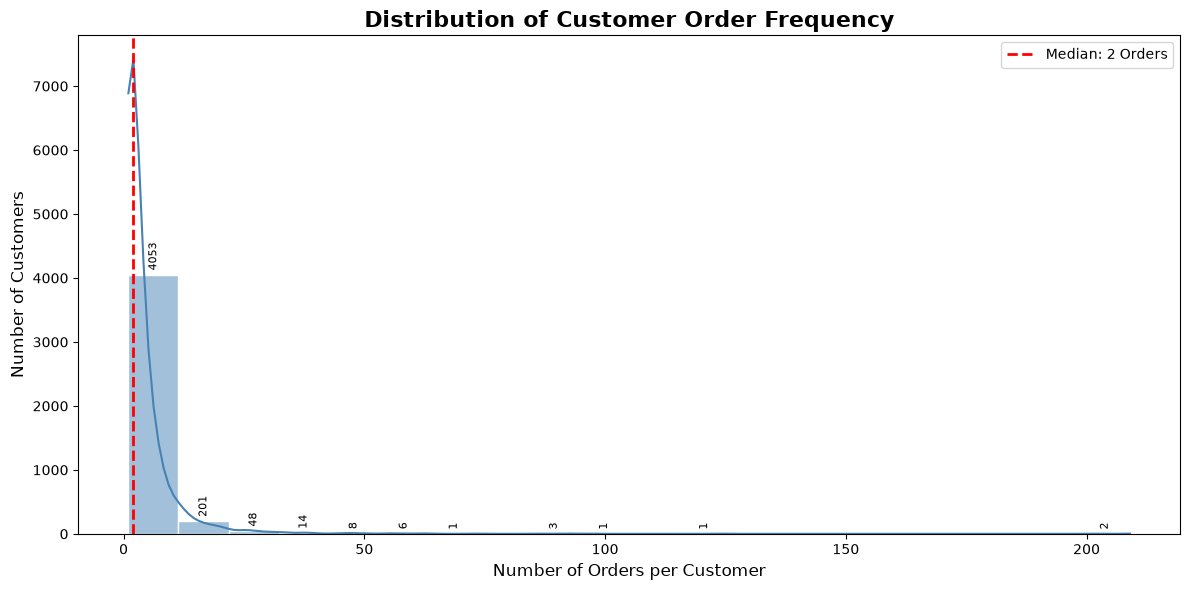

In [19]:
plt.figure(figsize=(12, 6))

ax = sns.histplot(
    customer_orders,
    bins=20,
    kde=True,
    color="steelblue",
    edgecolor="white"
)

median_orders = customer_orders.median()

plt.axvline(
    median_orders,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_orders:.0f} Orders"
)

# Display customer counts above histogram bars
for patch in ax.patches:
    height = patch.get_height()

    if height > 0:
        ax.annotate(
            f"{int(height)}",
            xy=(patch.get_x() + patch.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

plt.title(
    "Distribution of Customer Order Frequency",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Orders per Customer", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.legend()
plt.tight_layout()

plt.savefig(
    "../visualizations/customer_order_frequency_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 4. RFM Feature Engineering

RFM (Recency, Frequency, and Monetary) analysis is used to understand customer purchasing behavior and create customer-level features for segmentation.

The three RFM metrics are defined as follows:

- **Recency (R):** Number of days since a customer's most recent purchase.
- **Frequency (F):** Total number of unique invoices associated with a customer.
- **Monetary (M):** Total spending amount generated by a customer.

A reference date is established to calculate customer recency. The three metrics are aggregated at the customer level to create the RFM dataset.

The resulting RFM dataset is saved as `rfm_dataset.csv` for further analysis.


In [20]:
# Set the reference date to one day after the latest transaction
snapshot_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate the number of days since each customer's last purchase
customer_recency = (
    clean_df.groupby("CustomerID")["InvoiceDate"]
    .max()
    .apply(lambda date: (snapshot_date - date).days)
)

print("Recency Statistics:")
print(customer_recency.describe())

Recency Statistics:
count    4338.000000
mean       92.536422
std       100.014169
min         1.000000
25%        18.000000
50%        51.000000
75%       142.000000
max       374.000000
Name: InvoiceDate, dtype: float64


In [21]:
# Calculate the number of unique purchase invoices per customer
customer_frequency = (
    clean_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

# Display frequency statistics
print("Frequency Statistics:")
print(customer_frequency.describe())

Frequency Statistics:
count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: InvoiceNo, dtype: float64


In [22]:
# Calculate revenue generated by each transaction line
clean_df["TotalAmount"] = clean_df["Quantity"] * clean_df["UnitPrice"]

# Calculate total spending for each customer
customer_monetary = (
    clean_df.groupby("CustomerID")["TotalAmount"]
    .sum()
)

# Display monetary statistics
print("Monetary Statistics:")
print(customer_monetary.describe())

Monetary Statistics:
count      4338.000000
mean       2048.688081
std        8985.230220
min           3.750000
25%         306.482500
50%         668.570000
75%        1660.597500
max      280206.020000
Name: TotalAmount, dtype: float64


In [23]:
rfm_df = pd.DataFrame({
    "Recency": customer_recency,
    "Frequency": customer_frequency,
    "Monetary": customer_monetary
})

display(rfm_df.head())

print("RFM Dataset Shape:", rfm_df.shape)
print("\nMissing Values:")
print(rfm_df.isnull().sum())

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


RFM Dataset Shape: (4338, 3)

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [24]:
rfm_df.to_csv("../data/processed/rfm_dataset.csv", index=True)

print("RFM dataset saved successfully!")

RFM dataset saved successfully!



## 5. Feature Selection and Scaling

The RFM features are prepared for K-Means clustering by reducing skewness and standardizing feature values.

The following steps are performed:

- Examine the skewness of Recency, Frequency, and Monetary features.
- Apply logarithmic transformation using `np.log1p()` to reduce skewness.
- Standardize the transformed features using `StandardScaler`.
- Save the scaled RFM dataset as `rfm_scaled.csv`.

Feature scaling is important because K-Means uses distance-based calculations. Standardization ensures that features with larger numerical ranges do not dominate the clustering process.


RFM Feature Skewness:
Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64


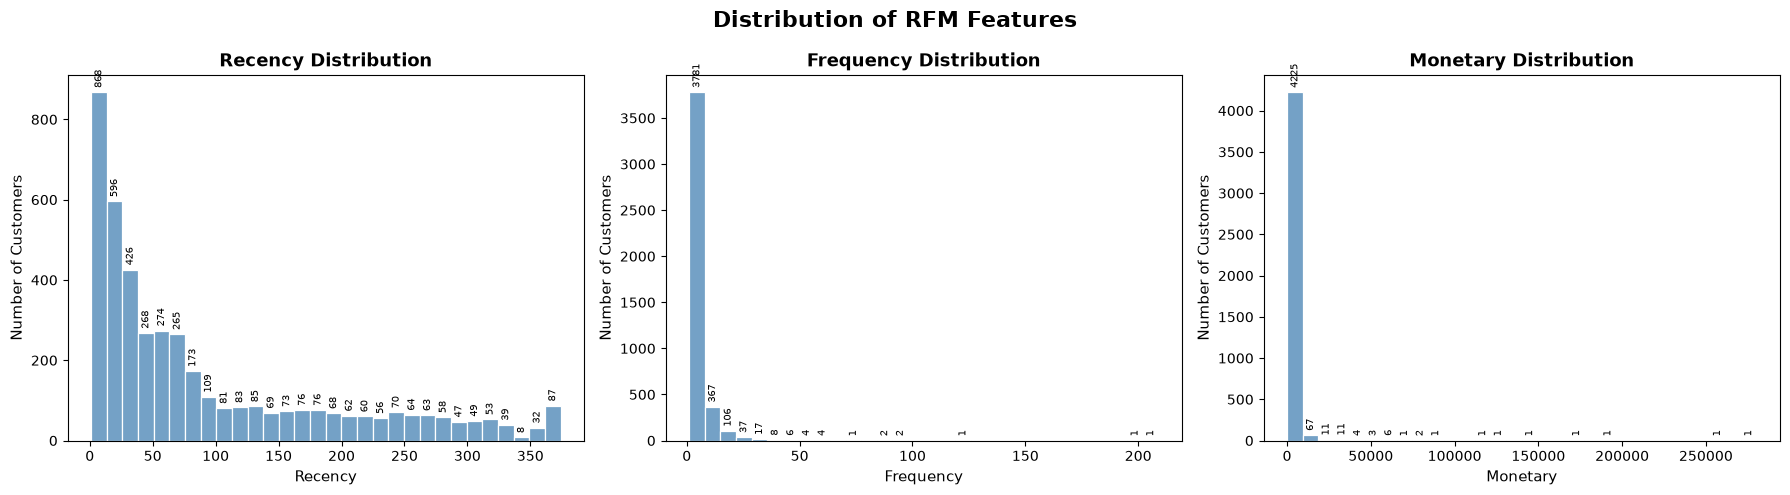

In [25]:
print("RFM Feature Skewness:")
print(rfm_df.skew())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for column, ax in zip(rfm_df.columns, axes):
    sns.histplot(
        rfm_df[column],
        bins=30,
        color="steelblue",
        edgecolor="white",
        ax=ax
    )

    # Display customer counts above histogram bars
    for patch in ax.patches:
        height = patch.get_height()

        if height > 0:
            ax.annotate(
                f"{int(height)}",
                xy=(patch.get_x() + patch.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=7,
                rotation=90
            )

    ax.set_title(f"{column} Distribution", fontsize=13, fontweight="bold")
    ax.set_xlabel(column, fontsize=11)
    ax.set_ylabel("Number of Customers", fontsize=11)

fig.suptitle(
    "Distribution of RFM Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../visualizations/rfm_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
rfm_log = np.log1p(rfm_df)

print("Skewness After Log Transformation:")
print(rfm_log.skew())

Skewness After Log Transformation:
Recency     -0.379169
Frequency    1.208652
Monetary     0.396599
dtype: float64


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm_log.columns,
    index=rfm_log.index
)

print("Scaled RFM Feature Statistics:")
print(rfm_scaled.describe().round(3))

Scaled RFM Feature Statistics:
        Recency  Frequency  Monetary
count  4338.000   4338.000  4338.000
mean     -0.000     -0.000    -0.000
std       1.000      1.000     1.000
min      -2.341     -0.955    -3.998
25%      -0.661     -0.955    -0.684
50%       0.090     -0.362    -0.065
75%       0.845      0.653     0.657
max       1.564      5.859     4.732


In [28]:
rfm_scaled.to_csv("../data/processed/rfm_scaled.csv", index=True)

print("Scaled RFM dataset saved successfully!")

Scaled RFM dataset saved successfully!



## 6. Optimal Number of Clusters

The optimal number of clusters is investigated before training the final K-Means model.

Two evaluation approaches are used:

- **Elbow Method:** Examines the reduction in inertia as the number of clusters increases. The elbow point indicates where additional clusters provide diminishing improvements.
- **Silhouette Score:** Measures how well customers fit within their assigned clusters compared with other clusters. Higher scores indicate better-separated clusters.

The candidate cluster counts are evaluated using both methods. Cluster size distribution is also examined to assess the resulting customer groups.

The results are used to select an appropriate number of clusters for customer segmentation.


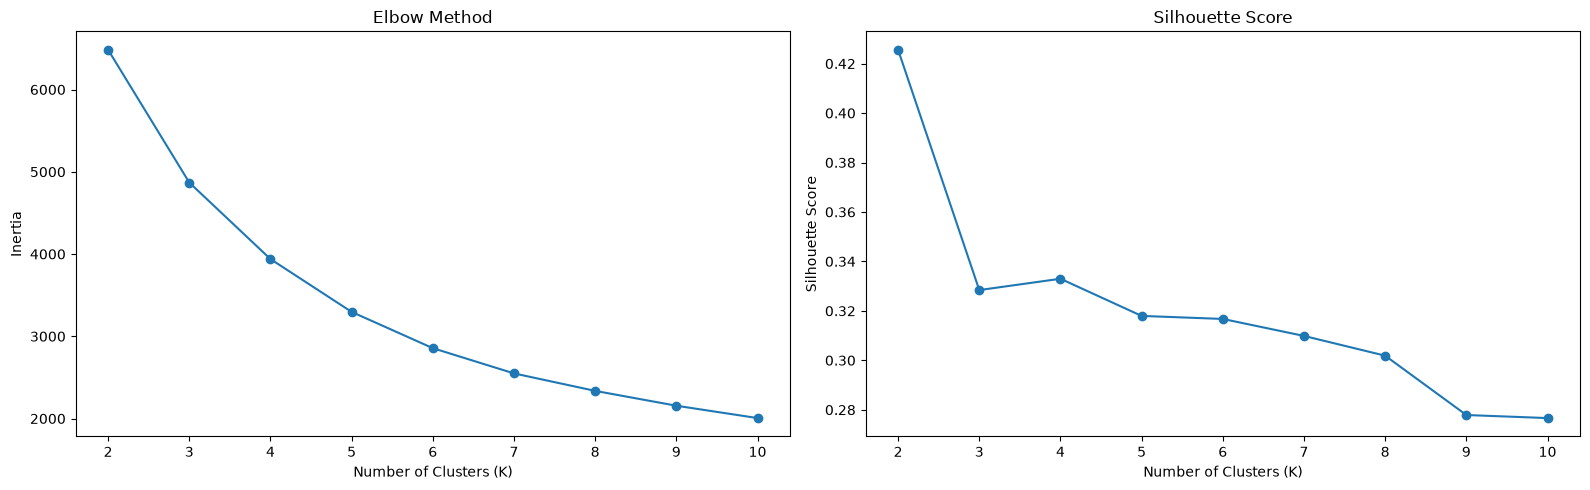

In [29]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        rfm_scaled,
        cluster_labels,
        sample_size=2000,
        random_state=42
    )
    silhouette_values.append(score)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()

plt.savefig("../visualizations/optimal_cluster_selection.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [30]:
cluster_size_results = {}

for k in [3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    cluster_size_results[k] = cluster_sizes

    print(f"\nCluster Sizes for K = {k}")
    print(cluster_sizes)
    print("Cluster Percentages:")
    print((cluster_sizes / len(rfm_scaled) * 100).round(2))


Cluster Sizes for K = 3
0     769
1    1872
2    1697
Name: count, dtype: int64
Cluster Percentages:
0    17.73
1    43.15
2    39.12
Name: count, dtype: float64

Cluster Sizes for K = 4
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64
Cluster Percentages:
0    16.44
1    37.39
2    19.29
3    26.88
Name: count, dtype: float64

Cluster Sizes for K = 5
0     834
1     938
2    1209
3    1018
4     339
Name: count, dtype: int64
Cluster Percentages:
0    19.23
1    21.62
2    27.87
3    23.47
4     7.81
Name: count, dtype: float64



## 7. K-Means Clustering

K-Means clustering is applied to the scaled RFM features to group customers according to their purchasing behavior.

### 7.1 Final K-Means Model Training

The final K-Means model is trained using the selected number of clusters.

The model is configured with a fixed random state and multiple initializations to improve reproducibility and clustering stability.




In [31]:
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm_df["Cluster"] = kmeans_final.fit_predict(rfm_scaled)

print("K-Means Model Trained Successfully!")

print("\nCluster Distribution:")
print(rfm_df["Cluster"].value_counts().sort_index())

K-Means Model Trained Successfully!

Cluster Distribution:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


### 7.2 Cluster Assignment and Saving the Model

Each customer is assigned to a cluster based on the trained K-Means model.

The following outputs are saved:

- Customer-level RFM dataset with cluster labels as `rfm_dataset_with_clusters.csv`.
- Trained K-Means model as `kmeans_model.pkl`.

The saved model can be reused for future customer segmentation.

In [32]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

rfm_df.to_csv("../data/processed/rfm_dataset_with_clusters.csv")

joblib.dump(kmeans_final, "../models/kmeans_model.pkl")

print("Cluster assignments and K-Means model saved successfully!")

Cluster assignments and K-Means model saved successfully!



## 8. Cluster Evaluation

The clustering results are evaluated using internal evaluation metrics to assess cluster quality and separation.

### 8.1 Clustering Evaluation Metrics

The following metrics are calculated:

- **Silhouette Score:** Evaluates how well customers fit within their assigned clusters compared with other clusters. Higher values indicate better-defined clusters.
- **Davies–Bouldin Index:** Measures the similarity between clusters. Lower values indicate better-separated clusters.
- **Calinski–Harabasz Score:** Evaluates cluster separation and compactness. Higher values generally indicate better clustering structure.



In [33]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

silhouette = silhouette_score(rfm_scaled, rfm_df["Cluster"])
davies_bouldin = davies_bouldin_score(rfm_scaled, rfm_df["Cluster"])
calinski_harabasz = calinski_harabasz_score(rfm_scaled, rfm_df["Cluster"])

print("Clustering Evaluation Metrics:")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")
print(f"Calinski-Harabasz Score: {calinski_harabasz:.2f}")

Clustering Evaluation Metrics:
Silhouette Score: 0.3375
Davies-Bouldin Index: 1.0086
Calinski-Harabasz Score: 3328.34


### 8.2 Evaluation Summary

The calculated evaluation metrics are summarized to assess the quality of the final K-Means clustering model.


In [34]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score"
    ],
    "Value": [
        silhouette,
        davies_bouldin,
        calinski_harabasz
    ]
})

evaluation_summary

,Metric,Value
0,Silhouette Score,0.337517
1,Davies-Bouldin Index,1.008648
2,Calinski-Harabasz Score,3328.338320



## 9. Customer Segment Profiling

Customer segment profiling is performed to understand the purchasing behavior and characteristics of customers within each cluster.

### 9.1 RFM Analysis by Cluster

The average Recency, Frequency, and Monetary values are calculated for each cluster.

These profiles help compare customer activity, purchase frequency, and spending behavior across segments.



In [35]:
cluster_profile = rfm_df.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()

cluster_profile = cluster_profile.round(2)

cluster_profile

,Recency,Frequency,Monetary
Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


### 9.2 Customer Segment Distribution

The number of customers and their percentage contribution to each cluster are calculated to understand the distribution of customers across segments.


In [36]:
cluster_counts = rfm_df["Cluster"].value_counts().sort_index()

cluster_distribution = pd.DataFrame({
    "Customer Count": cluster_counts,
    "Percentage": (cluster_counts / len(rfm_df) * 100).round(2)
})

cluster_distribution

,Customer Count,Percentage
Cluster,,
0,713,16.44
1,1622,37.39
2,837,19.29
3,1166,26.88


### 9.3 Customer Segment Distribution Visualization

A bar chart is used to visualize the number of customers in each cluster and compare segment sizes.


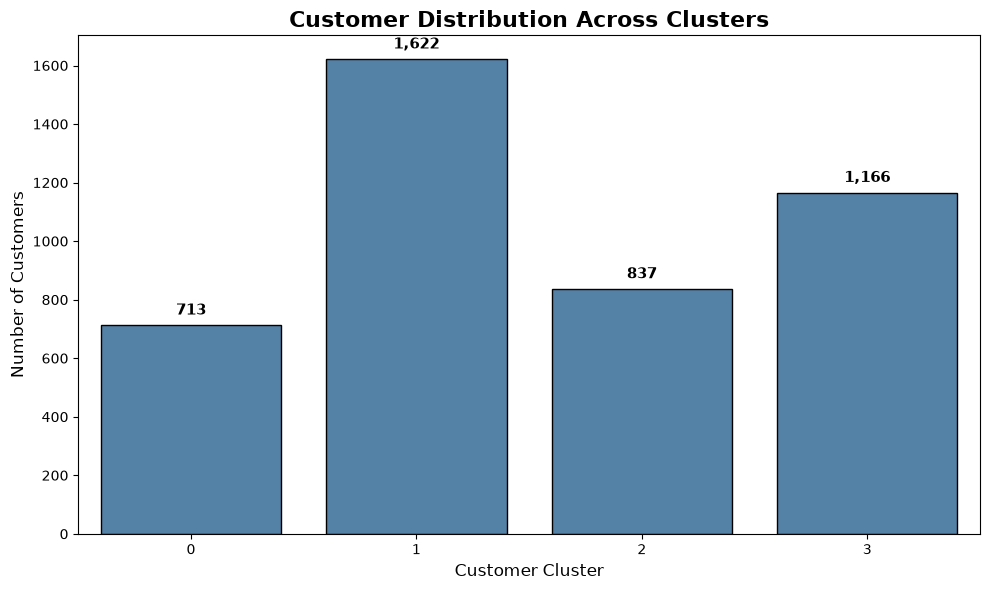

In [37]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=cluster_distribution.index,
    y=cluster_distribution["Customer Count"],
    color="steelblue",
    edgecolor="black"
)

# Display customer counts above bars
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{int(height):,}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Customer Distribution Across Clusters",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Cluster", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.tight_layout()

plt.savefig(
    "../visualizations/customer_cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Cluster Visualization

Cluster visualization is performed to understand how customers are distributed across the identified segments.

### 10.1 PCA-Based Cluster Visualization

Principal Component Analysis (PCA) is applied to the scaled RFM features to reduce the three-dimensional feature space into two principal components.

The two components are used to visualize the clustering structure while preserving as much variation in the data as possible.


In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm_df.index
)

pca_df["Cluster"] = rfm_df["Cluster"]

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.75078634 0.18786648]

Total Variance Explained:
0.9386528181989527


### 10.2 PCA Cluster Scatter Plot

A scatter plot is created using the two principal components.

Customers are colored according to their assigned cluster labels to examine cluster separation, distribution, and overlap.

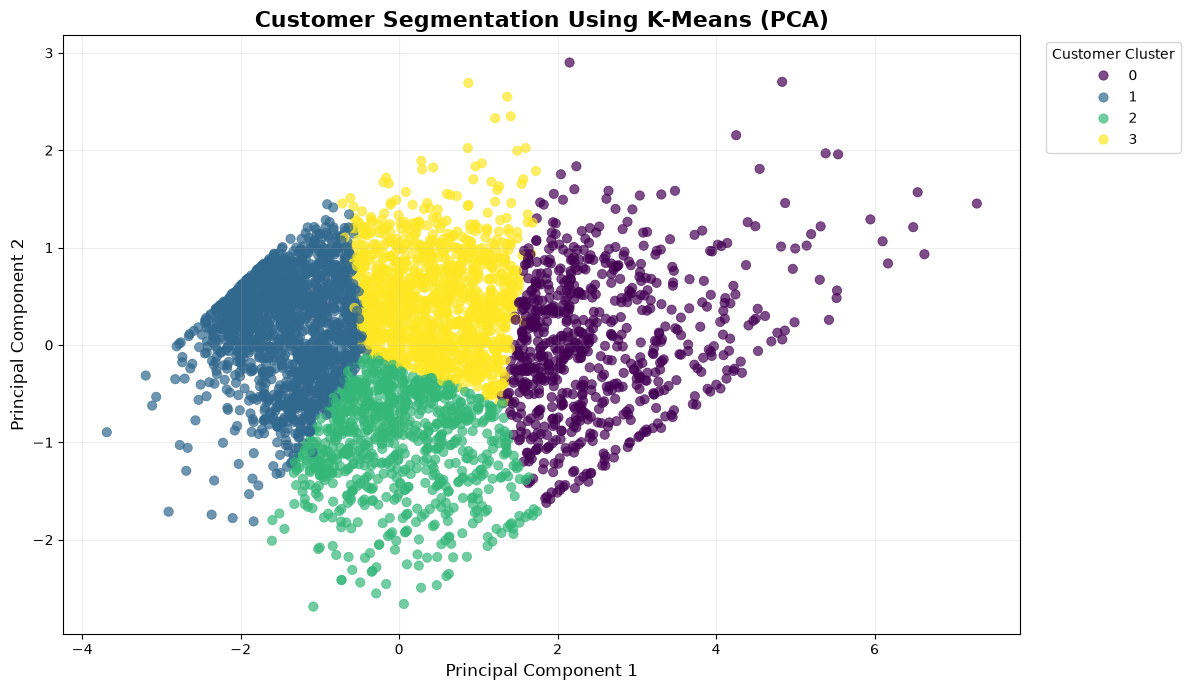

In [39]:
plt.figure(figsize=(12, 7))

ax = sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    s=45,
    alpha=0.7,
    edgecolor=None
)

plt.title(
    "Customer Segmentation Using K-Means (PCA)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)

plt.legend(
    title="Customer Cluster",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "../visualizations/customer_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 11. Business Insights and Recommendations

The customer segments are interpreted based on their RFM characteristics to identify meaningful customer purchasing patterns and business opportunities.

### 11.1 Business Insights

Key insights are derived from the customer segment profiles and cluster distribution.

These insights help identify valuable customers, inactive customers, and customers with opportunities for increased engagement.



In [40]:
business_insights = cluster_profile.copy()

business_insights["Customer Count"] = cluster_distribution["Customer Count"]
business_insights["Customer Percentage"] = cluster_distribution["Percentage"]

business_insights.round(2)

,Recency,Frequency,Monetary,Customer Count,Customer Percentage
Cluster,,,,,
0,12.17,13.75,8088.02,713,16.44
1,181.51,1.32,341.00,1622,37.39
2,17.70,2.19,557.32,837,19.29
3,71.64,4.08,1801.78,1166,26.88


### 11.2 Business Recommendations

Business recommendations are developed based on the identified customer segments.

The recommendations focus on:

- Retaining high-value customers.
- Re-engaging inactive customers.
- Encouraging repeat purchases.
- Improving customer engagement.
- Increasing customer lifetime value.


In [41]:
business_recommendations = {
    "Cluster 0": "Reward high-value customers with loyalty programs, exclusive offers, and premium services.",
    "Cluster 1": "Launch re-engagement campaigns, personalized discounts, and targeted promotional emails.",
    "Cluster 2": "Encourage repeat purchases through product recommendations, follow-up offers, and cross-selling.",
    "Cluster 3": "Strengthen customer loyalty through personalized rewards, retention campaigns, and upselling."
}

for cluster, recommendation in business_recommendations.items():
    print(f"{cluster}: {recommendation}\n")

Cluster 0: Reward high-value customers with loyalty programs, exclusive offers, and premium services.

Cluster 1: Launch re-engagement campaigns, personalized discounts, and targeted promotional emails.

Cluster 2: Encourage repeat purchases through product recommendations, follow-up offers, and cross-selling.

Cluster 3: Strengthen customer loyalty through personalized rewards, retention campaigns, and upselling.



## 12. Conclusion

This project applied K-Means clustering to customer transaction data to identify distinct customer segments using Recency, Frequency, and Monetary (RFM) analysis.

The analysis identified four customer segments with different purchasing behaviors and spending patterns. Cluster evaluation metrics and PCA-based visualization were used to assess the clustering results.

The identified customer segments provide meaningful insights into customer purchasing behavior and support targeted marketing strategies, customer retention initiatives, and customer engagement improvements.

Overall, this project demonstrates how unsupervised machine learning can support customer segmentation and data-driven business decision-making.